Melewati unduhan Kaggle (folder dataset/ sudah terisi atau PAKAI_KAGGLE=False).
Berhasil memuat 25 citra, ukuran seragam (256, 256), mode grayscale.


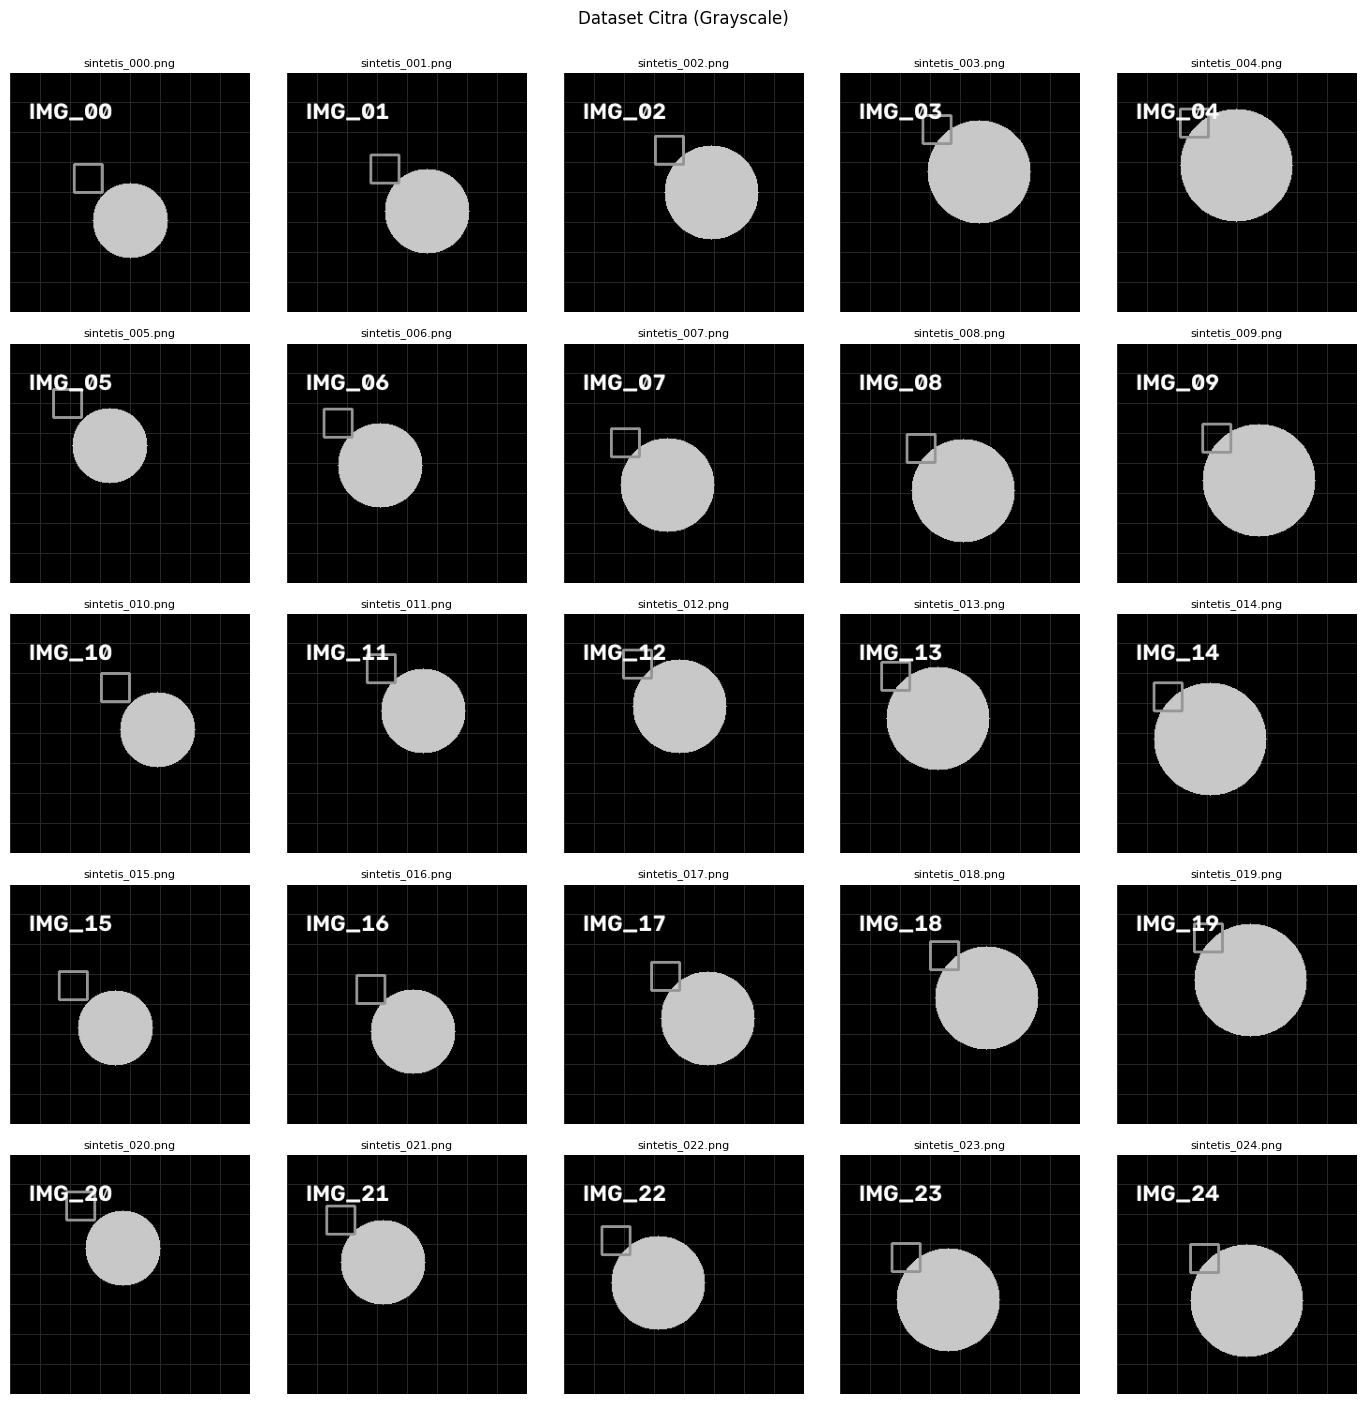

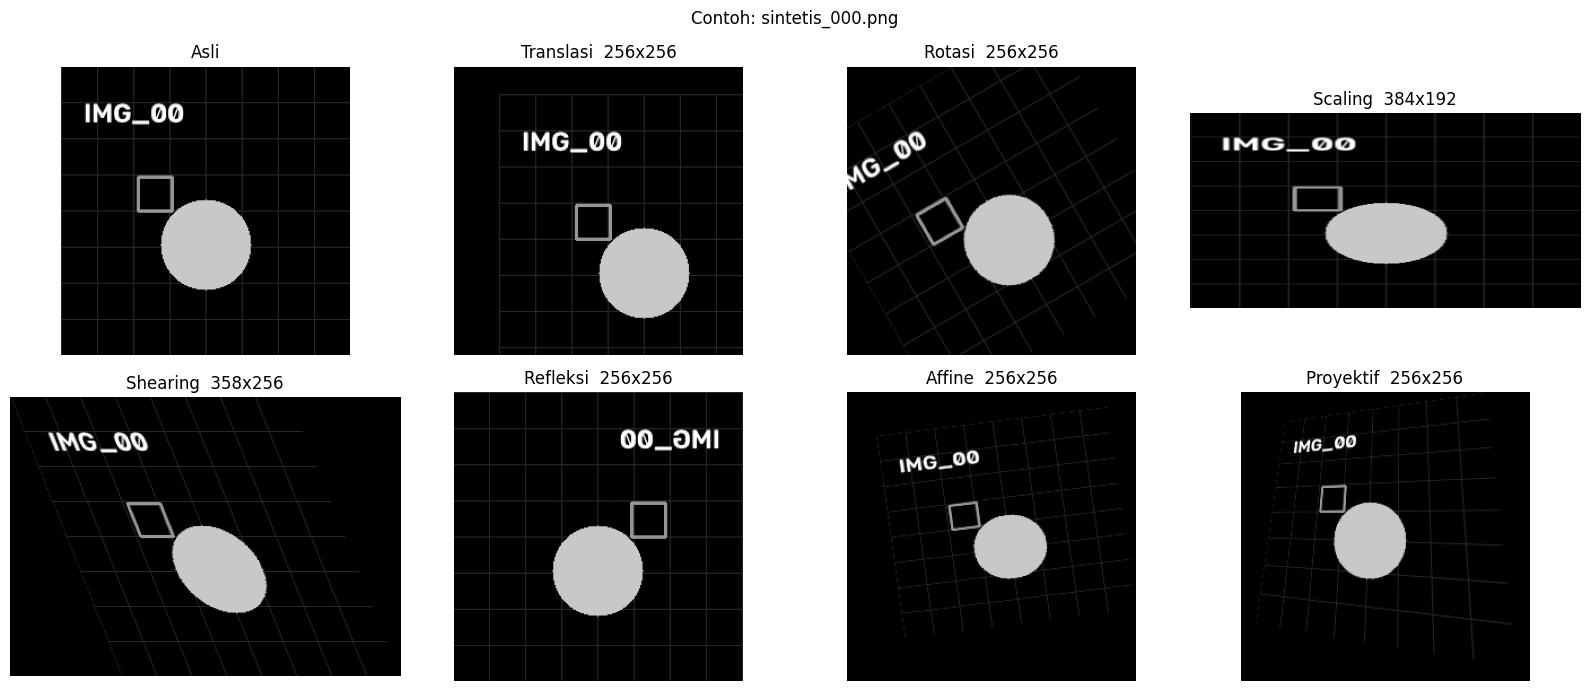

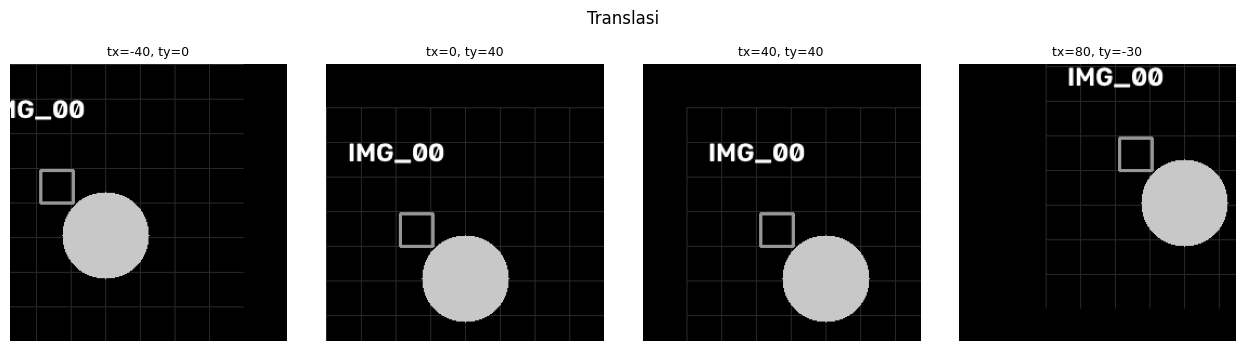

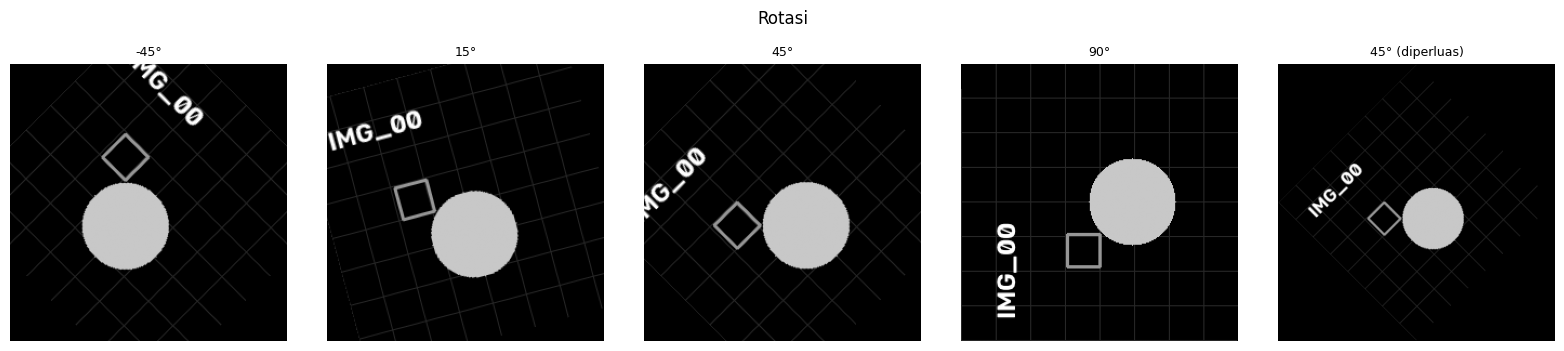

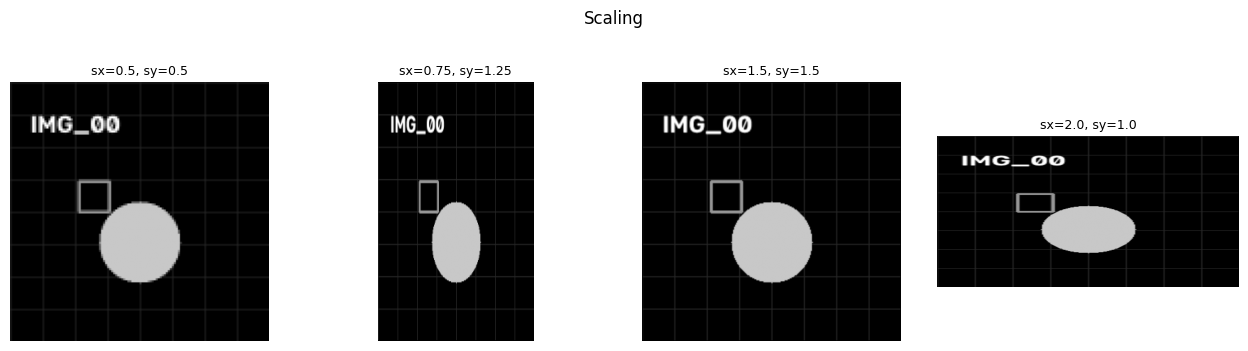

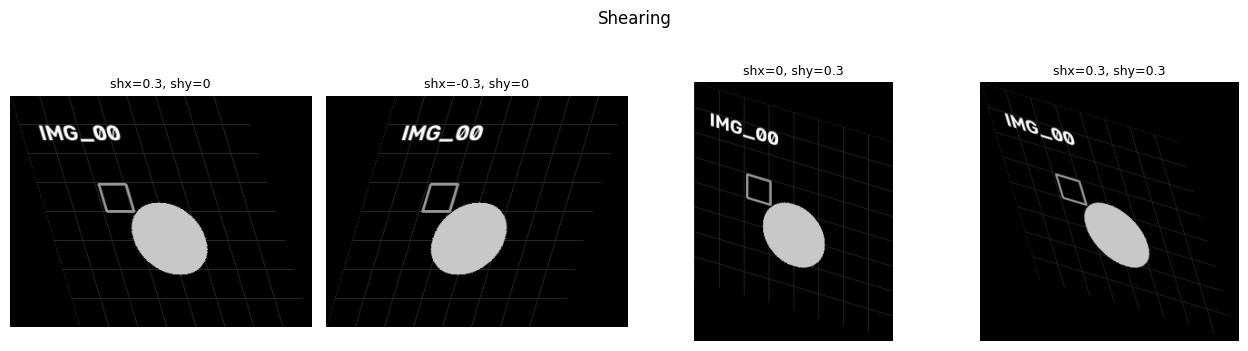

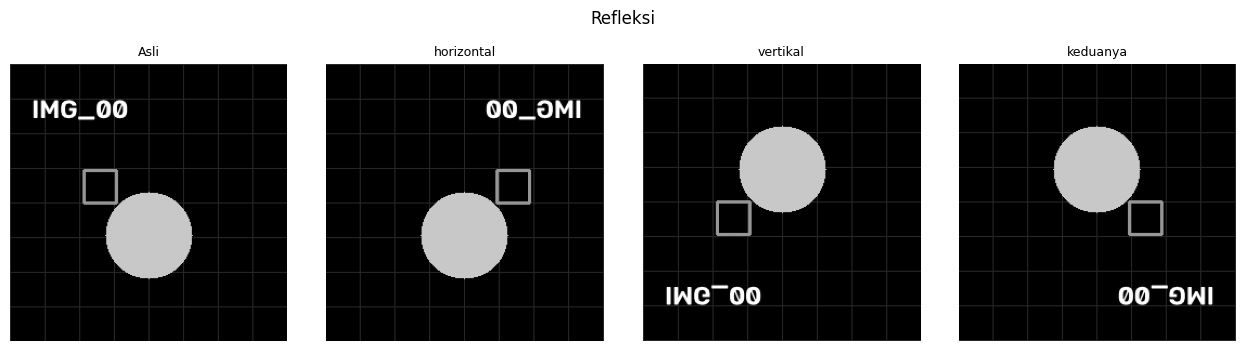

1_Translasi   : 25 citra tersimpan di 'hasil/1_Translasi/'
2_Rotasi      : 25 citra tersimpan di 'hasil/2_Rotasi/'
3_Scaling     : 25 citra tersimpan di 'hasil/3_Scaling/'
4_Shearing    : 25 citra tersimpan di 'hasil/4_Shearing/'
5_Refleksi    : 25 citra tersimpan di 'hasil/5_Refleksi/'
6_Affine      : 25 citra tersimpan di 'hasil/6_Affine/'
7_Proyektif   : 25 citra tersimpan di 'hasil/7_Proyektif/'


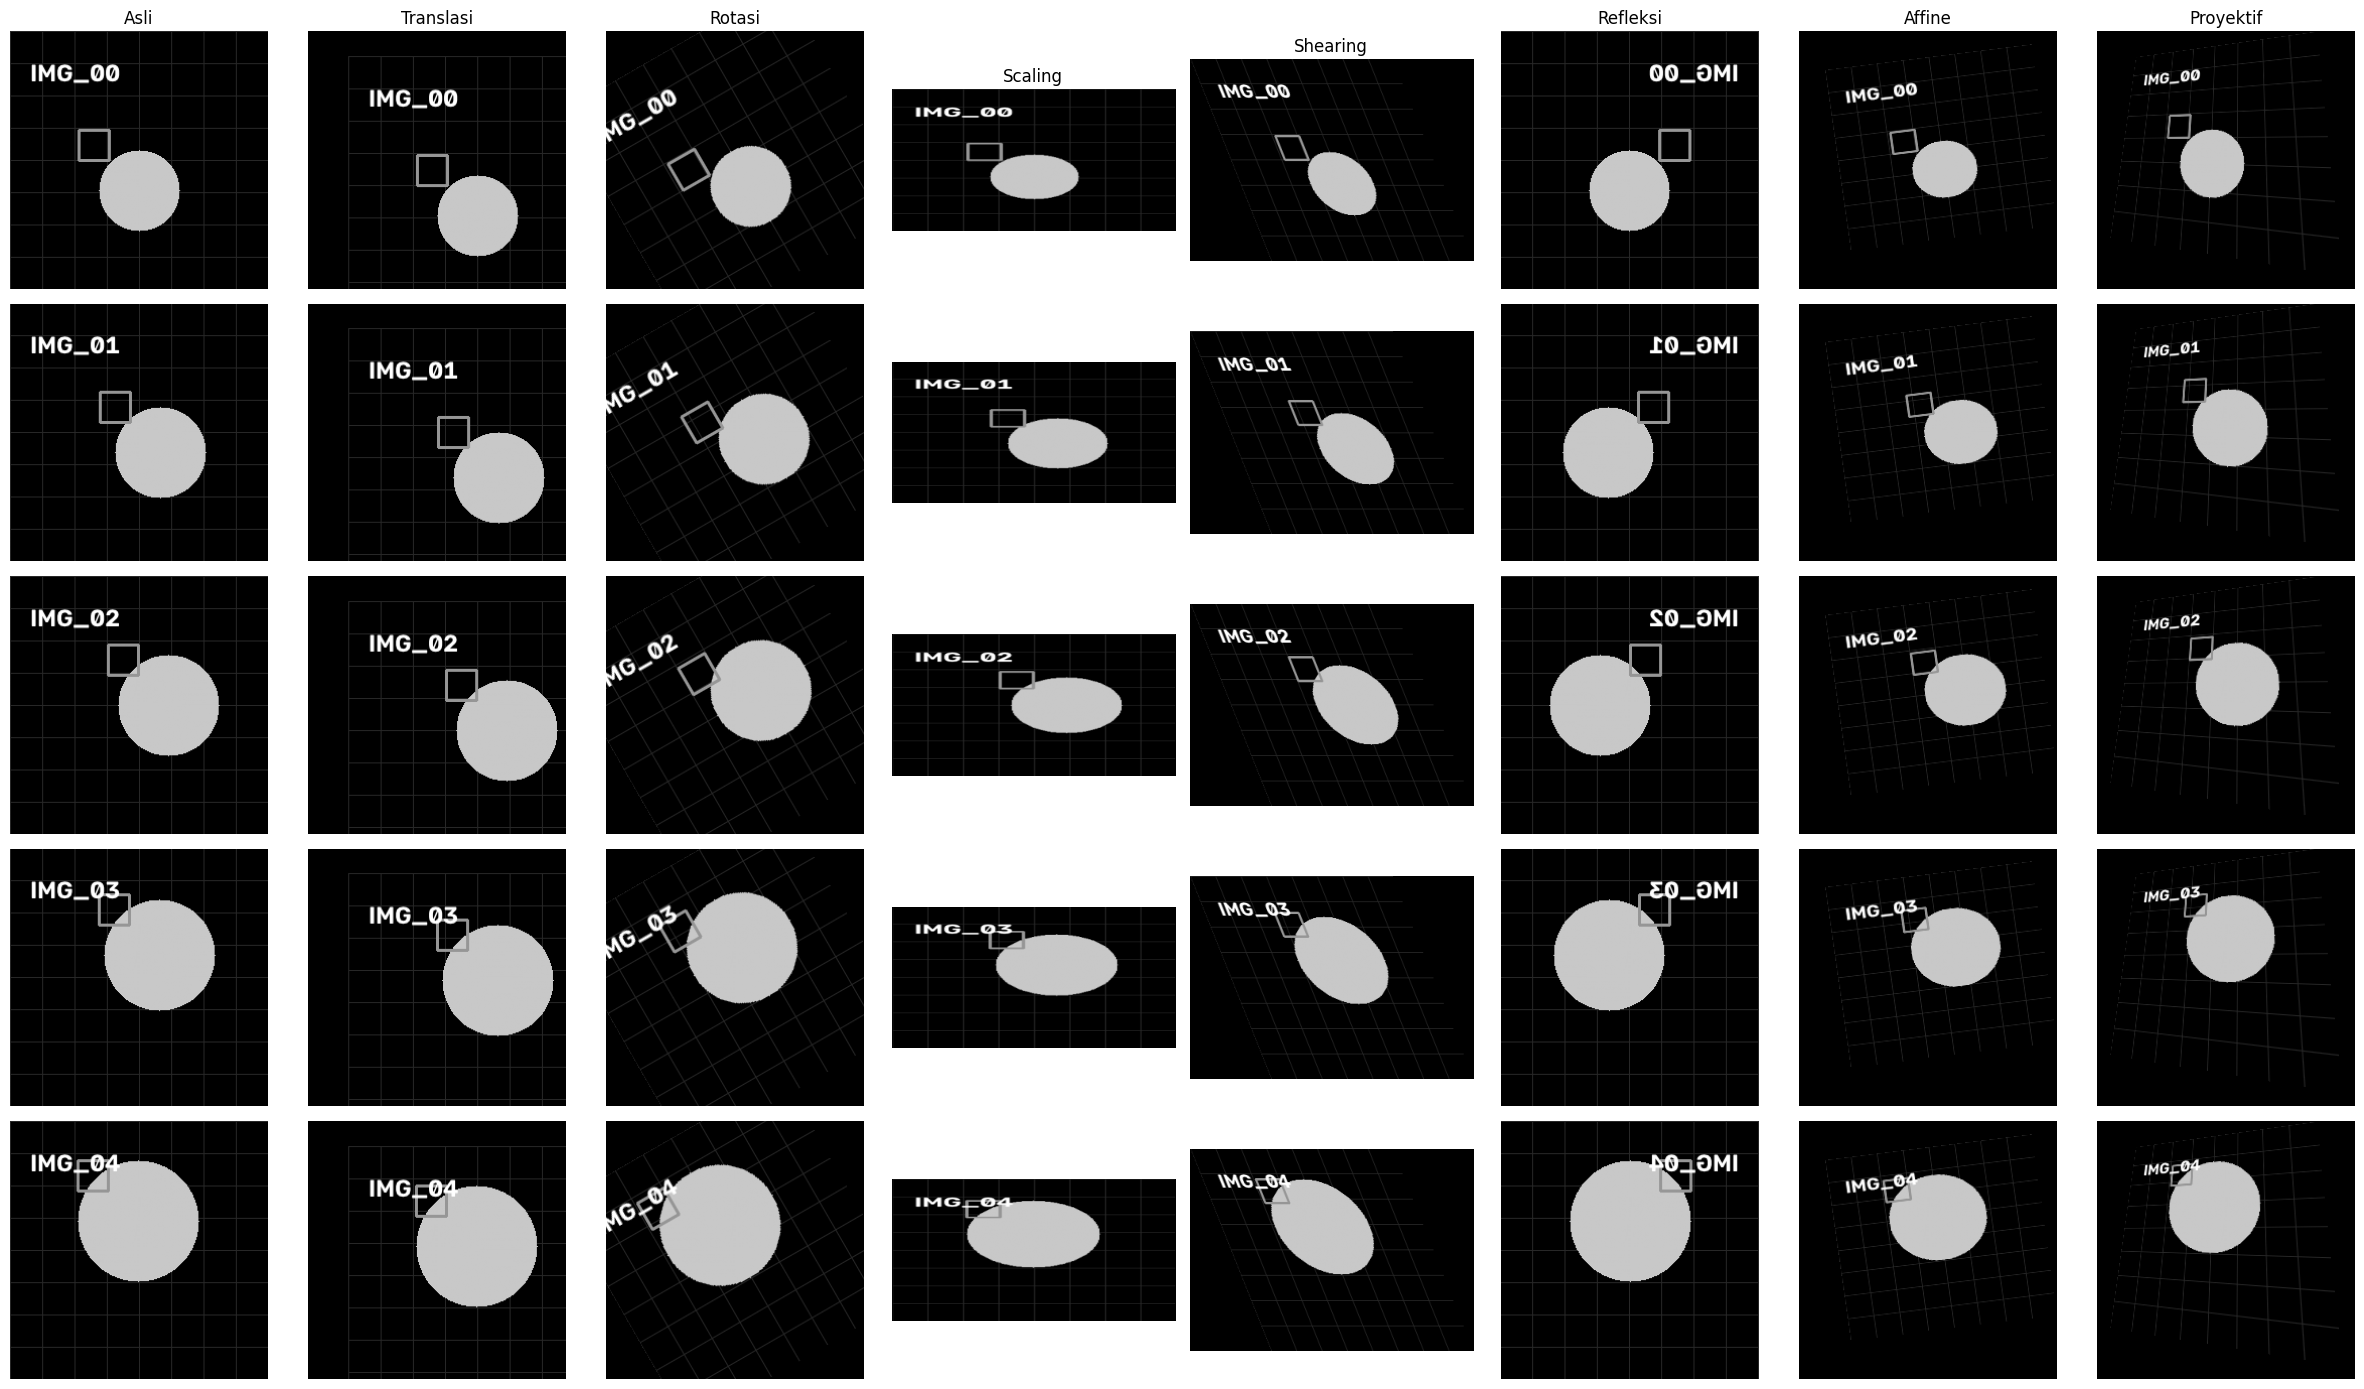

Rotasi    -> rata-rata selisih piksel: 0.069
Translasi -> rata-rata selisih piksel: 0.0
Proyektif -> rata-rata selisih piksel: 0.073
Matriks homografi:
 [[ 5.0465e-01 -1.1025e-01  3.8400e+01]
 [-1.0039e-01  5.4499e-01  2.5600e+01]
 [-9.1000e-04 -7.7000e-04  1.0000e+00]]


In [9]:
# ======================================================================
# 1. Import & Konfigurasi
# ======================================================================
import os
import glob
import numpy as np
import cv2                      # hanya dipakai untuk membaca/menyimpan file & konversi grayscale
import matplotlib.pyplot as plt

DATASET_DIR = "dataset"         # folder berisi citra input
OUTPUT_DIR  = "hasil"           # folder penyimpanan hasil
UKURAN_SERAGAM = (256, 256)     # (lebar, tinggi) -> semua citra disamakan ukurannya
MIN_CITRA = 20

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ======================================================================
# 1b. Ambil Dataset dari Kaggle (opsional)
# ======================================================================
import shutil

PAKAI_KAGGLE = False
KAGGLE_SLUG  = "bastan/dogs-vs-cats-500"   # <-- Menggunakan dataset valid publik
JUMLAH_AMBIL = 25                       # ambil 25 citra (minimal tugas = 20)


def salin_citra(sumber, tujuan, jumlah):
    """Mengambil `jumlah` citra pertama (urut nama) dari folder sumber (rekursif) ke folder tujuan."""
    ext = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
    semua = []
    for root, _, files in os.walk(sumber):
        for f in files:
            if f.lower().endswith(ext):
                semua.append(os.path.join(root, f))
    semua.sort()
    if len(semua) < jumlah:
        raise ValueError(f"Hanya ada {len(semua)} citra di dataset, butuh {jumlah}.")
    os.makedirs(tujuan, exist_ok=True)
    for i, p in enumerate(semua[:jumlah]):
        nama = f"{i:03d}_" + os.path.basename(p)
        shutil.copy(p, os.path.join(tujuan, nama))
    print(f"{jumlah} citra disalin ke '{tujuan}/'")


if PAKAI_KAGGLE and not glob.glob(os.path.join(DATASET_DIR, "*")):
    # pip install kagglehub   (jalankan sekali jika belum terpasang)
    import kagglehub
    path_unduhan = kagglehub.dataset_download(KAGGLE_SLUG)
    print("Dataset diunduh ke:", path_unduhan)
    salin_citra(path_unduhan, DATASET_DIR, JUMLAH_AMBIL)
else:
    print("Melewati unduhan Kaggle (folder dataset/ sudah terisi atau PAKAI_KAGGLE=False).")

# ======================================================================
# 2. Load Dataset & Konversi Grayscale
# ======================================================================
def load_dataset(folder, ukuran=UKURAN_SERAGAM, minimal=MIN_CITRA):
    """Membaca semua citra di folder, mengubah ke grayscale dan menyeragamkan ukurannya.
    Return: list nama file, list array grayscale (uint8)."""
    ekstensi = ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff", "*.webp")
    path_list = []
    for e in ekstensi:
        path_list += glob.glob(os.path.join(folder, e))
        path_list += glob.glob(os.path.join(folder, e.upper()))
    path_list = sorted(set(path_list))

    nama, citra = [], []
    for p in path_list:
        img = cv2.imread(p, cv2.IMREAD_COLOR)
        if img is None:
            print("Gagal membaca:", p)
            continue
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)        # konversi ke grayscale
        gray = cv2.resize(gray, ukuran, interpolation=cv2.INTER_AREA)
        nama.append(os.path.basename(p))
        citra.append(gray)

    if len(citra) < minimal:
        raise ValueError(f"Citra di '{folder}' hanya {len(citra)}, minimal {minimal}.")
    print(f"Berhasil memuat {len(citra)} citra, ukuran seragam {ukuran}, mode grayscale.")
    return nama, citra


nama_file, dataset = load_dataset(DATASET_DIR)

# Pratinjau dataset
n = len(dataset)
kolom = 5
baris = int(np.ceil(n / kolom))
plt.figure(figsize=(14, 2.8 * baris))
for i, (nm, im) in enumerate(zip(nama_file, dataset)):
    plt.subplot(baris, kolom, i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(nm, fontsize=8)
    plt.axis("off")
plt.suptitle("Dataset Citra (Grayscale)", y=1.0)
plt.tight_layout()
plt.show()

# ======================================================================
# 3. Fungsi Inti (Warping)
# ======================================================================
def _bilinear(img, xs, ys):
    """Sampling bilinear pada koordinat sumber (xs, ys). Di luar batas -> 0."""
    h, w = img.shape
    x0 = np.floor(xs).astype(np.int64)
    y0 = np.floor(ys).astype(np.int64)
    x1, y1 = x0 + 1, y0 + 1
    dx, dy = xs - x0, ys - y0

    valid = (xs >= 0) & (xs <= w - 1) & (ys >= 0) & (ys <= h - 1)

    x0c, x1c = np.clip(x0, 0, w - 1), np.clip(x1, 0, w - 1)
    y0c, y1c = np.clip(y0, 0, h - 1), np.clip(y1, 0, h - 1)

    f = img.astype(np.float64)
    atas  = f[y0c, x0c] * (1 - dx) + f[y0c, x1c] * dx
    bawah = f[y1c, x0c] * (1 - dx) + f[y1c, x1c] * dx
    hasil = atas * (1 - dy) + bawah * dy
    hasil[~valid] = 0
    return np.clip(np.rint(hasil), 0, 255).astype(np.uint8)


def _grid_tujuan(out_shape):
    """Grid koordinat piksel tujuan, bentuk (H_out, W_out)."""
    H, W = out_shape
    xs, ys = np.meshgrid(np.arange(W), np.arange(H))
    return xs.astype(np.float64), ys.astype(np.float64)


def warp_affine(img, M, out_shape=None):
    """Warp dengan matriks affine 2x3 (arah maju: sumber -> tujuan)."""
    if out_shape is None:
        out_shape = img.shape
    M3 = np.vstack([np.asarray(M, dtype=np.float64), [0, 0, 1]])
    inv = np.linalg.inv(M3)
    xt, yt = _grid_tujuan(out_shape)
    xs = inv[0, 0] * xt + inv[0, 1] * yt + inv[0, 2]
    ys = inv[1, 0] * xt + inv[1, 1] * yt + inv[1, 2]
    return _bilinear(img, xs, ys)


def warp_perspective(img, H, out_shape=None):
    """Warp dengan matriks homografi 3x3 (arah maju: sumber -> tujuan)."""
    if out_shape is None:
        out_shape = img.shape
    inv = np.linalg.inv(np.asarray(H, dtype=np.float64))
    xt, yt = _grid_tujuan(out_shape)
    w = inv[2, 0] * xt + inv[2, 1] * yt + inv[2, 2]
    w[np.abs(w) < 1e-12] = 1e-12
    xs = (inv[0, 0] * xt + inv[0, 1] * yt + inv[0, 2]) / w
    ys = (inv[1, 0] * xt + inv[1, 1] * yt + inv[1, 2]) / w
    return _bilinear(img, xs, ys)


def _kanvas_otomatis(M, shape):
    """Hitung ukuran kanvas & geser matriks supaya seluruh citra hasil transformasi muat."""
    h, w = shape
    sudut = np.array([[0, 0, 1], [w - 1, 0, 1], [0, h - 1, 1], [w - 1, h - 1, 1]], dtype=np.float64).T
    M3 = np.vstack([np.asarray(M, dtype=np.float64), [0, 0, 1]])
    p = M3 @ sudut
    xmin, xmax = p[0].min(), p[0].max()
    ymin, ymax = p[1].min(), p[1].max()
    geser = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1]], dtype=np.float64)
    M_baru = (geser @ M3)[:2]
    W = int(np.ceil(xmax - xmin)) + 1
    H = int(np.ceil(ymax - ymin)) + 1
    return M_baru, (H, W)

# ======================================================================
# 4. Fungsi Transformasi
# ======================================================================
def translasi(img, tx, ty):
    """Menggeser citra sejauh tx (horizontal) dan ty (vertikal) piksel."""
    M = np.array([[1, 0, tx],
                  [0, 1, ty]], dtype=np.float64)
    return warp_affine(img, M, img.shape)

# ======================================================================
# 4.2 Rotasi
# ======================================================================
def rotasi(img, sudut, pusat=None, perluas=False):
    """Memutar citra sebesar `sudut` derajat (positif = berlawanan arah jarum jam).
    pusat   : (cx, cy), default pusat citra
    perluas : True -> kanvas diperbesar agar seluruh citra tetap terlihat."""
    h, w = img.shape
    if pusat is None:
        pusat = ((w - 1) / 2.0, (h - 1) / 2.0)
    cx, cy = pusat
    t = np.deg2rad(sudut)
    c, s = np.cos(t), np.sin(t)
    # koordinat citra: sumbu y ke bawah, sehingga rotasi CCW memakai tanda berikut
    R = np.array([[c,  s],
                  [-s, c]])
    trans = np.array([cx, cy]) - R @ np.array([cx, cy])
    M = np.hstack([R, trans.reshape(2, 1)])
    if perluas:
        M, out_shape = _kanvas_otomatis(M, img.shape)
        return warp_affine(img, M, out_shape)
    return warp_affine(img, M, img.shape)

# ======================================================================
# 4.3 Scaling
# ======================================================================
def scaling(img, sx, sy=None):
    """Memperbesar (>1) atau memperkecil (<1) citra. Ukuran output = ukuran input x faktor skala."""
    if sy is None:
        sy = sx
    h, w = img.shape
    W = max(1, int(round(w * sx)))
    H = max(1, int(round(h * sy)))
    # pemetaan agar pusat piksel tetap sejajar (pixel-center alignment)
    M = np.array([[sx, 0,  (sx - 1) / 2.0],
                  [0,  sy, (sy - 1) / 2.0]], dtype=np.float64)
    return warp_affine(img, M, (H, W))

# ======================================================================
# 4.4 Shearing (Skewing)
# ======================================================================
def shearing(img, shx=0.0, shy=0.0, perluas=True):
    """Shear horizontal (shx) dan/atau vertikal (shy).
    perluas=True -> kanvas disesuaikan agar hasil tidak terpotong."""
    M = np.array([[1,   shx, 0],
                  [shy, 1,   0]], dtype=np.float64)
    if perluas:
        M, out_shape = _kanvas_otomatis(M, img.shape)
        return warp_affine(img, M, out_shape)
    return warp_affine(img, M, img.shape)

# ======================================================================
# 4.5 Refleksi
# ======================================================================
def refleksi(img, mode="horizontal"):
    """Refleksi citra.
    mode: 'horizontal' (cermin kiri-kanan, terhadap sumbu vertikal),
          'vertikal'   (cermin atas-bawah, terhadap sumbu horizontal),
          'keduanya'   (terhadap titik pusat)."""
    h, w = img.shape
    if mode == "horizontal":
        M = np.array([[-1, 0, w - 1], [0, 1, 0]], dtype=np.float64)
    elif mode == "vertikal":
        M = np.array([[1, 0, 0], [0, -1, h - 1]], dtype=np.float64)
    elif mode == "keduanya":
        M = np.array([[-1, 0, w - 1], [0, -1, h - 1]], dtype=np.float64)
    else:
        raise ValueError("mode harus 'horizontal', 'vertikal', atau 'keduanya'")
    return warp_affine(img, M, img.shape)

# ======================================================================
# 4.6 Transformasi Affine
# ======================================================================
def hitung_matriks_affine(titik_src, titik_dst):
    """Menghitung matriks affine 2x3 dari 3 pasang titik."""
    src = np.asarray(titik_src, dtype=np.float64)
    dst = np.asarray(titik_dst, dtype=np.float64)
    assert src.shape == (3, 2) and dst.shape == (3, 2), "Dibutuhkan tepat 3 titik (x, y)"
    A = np.hstack([src, np.ones((3, 1))])        # (3,3)
    # A @ M.T = dst  ->  M.T = A^-1 @ dst
    M = np.linalg.solve(A, dst).T                # (2,3)
    return M


def transformasi_affine(img, titik_src, titik_dst, out_shape=None):
    """Transformasi affine berdasarkan 3 pasang titik korespondensi."""
    M = hitung_matriks_affine(titik_src, titik_dst)
    return warp_affine(img, M, out_shape if out_shape else img.shape), M

# ======================================================================
# 4.7 Transformasi Proyektif (Perspective)
# ======================================================================
def hitung_matriks_proyektif(titik_src, titik_dst):
    """Menghitung homografi 3x3 dari 4 pasang titik (h33 = 1)."""
    src = np.asarray(titik_src, dtype=np.float64)
    dst = np.asarray(titik_dst, dtype=np.float64)
    assert src.shape == (4, 2) and dst.shape == (4, 2), "Dibutuhkan tepat 4 titik (x, y)"
    A, b = [], []
    for (x, y), (u, v) in zip(src, dst):
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y]); b.append(u)
        A.append([0, 0, 0, x, y, 1, -v * x, -v * y]); b.append(v)
    h = np.linalg.solve(np.array(A), np.array(b))
    return np.append(h, 1.0).reshape(3, 3)


def transformasi_proyektif(img, titik_src, titik_dst, out_shape=None):
    """Transformasi perspektif berdasarkan 4 pasang titik korespondensi."""
    H = hitung_matriks_proyektif(titik_src, titik_dst)
    return warp_perspective(img, H, out_shape if out_shape else img.shape), H

# ======================================================================
# 5. Parameter Transformasi
# ======================================================================
def titik_affine(shape):
    h, w = shape
    src = [[0, 0], [w - 1, 0], [0, h - 1]]
    dst = [[0.10 * w, 0.15 * h], [0.90 * w, 0.05 * h], [0.20 * w, 0.85 * h]]
    return src, dst


def titik_proyektif(shape):
    h, w = shape
    src = [[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]]
    dst = [[0.15 * w, 0.10 * h], [0.85 * w, 0.00 * h],
           [0.95 * w, 0.95 * h], [0.05 * w, 0.80 * h]]
    return src, dst


# Daftar transformasi: nama -> fungsi yang menerima citra dan mengembalikan hasil
TRANSFORMASI = {
    "1_Translasi":  lambda im: translasi(im, tx=40, ty=25),
    "2_Rotasi":     lambda im: rotasi(im, sudut=30),
    "3_Scaling":    lambda im: scaling(im, sx=1.5, sy=0.75),
    "4_Shearing":   lambda im: shearing(im, shx=0.4, shy=0.0),
    "5_Refleksi":   lambda im: refleksi(im, "horizontal"),
    "6_Affine":     lambda im: transformasi_affine(im, *titik_affine(im.shape))[0],
    "7_Proyektif":  lambda im: transformasi_proyektif(im, *titik_proyektif(im.shape))[0],
}

# ======================================================================
# 6. Uji Satu Citra: Seluruh Transformasi
# ======================================================================
def tampilkan_semua(img, judul="Citra"):
    plt.figure(figsize=(16, 7))
    plt.subplot(2, 4, 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title("Asli"); plt.axis("off")
    for i, (nama, fn) in enumerate(TRANSFORMASI.items(), start=2):
        hasil = fn(img)
        plt.subplot(2, 4, i)
        plt.imshow(hasil, cmap="gray", vmin=0, vmax=255)
        plt.title(f"{nama.split('_', 1)[1]}  {hasil.shape[1]}x{hasil.shape[0]}")
        plt.axis("off")
    plt.suptitle(judul)
    plt.tight_layout()
    plt.show()


tampilkan_semua(dataset[0], f"Contoh: {nama_file[0]}")

# ======================================================================
# 7. Variasi Parameter
# ======================================================================
def baris_variasi(judul, daftar):
    """daftar = list of (label, citra)"""
    plt.figure(figsize=(3.2 * len(daftar), 3.4))
    for i, (lb, im) in enumerate(daftar, start=1):
        plt.subplot(1, len(daftar), i)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(lb, fontsize=9); plt.axis("off")
    plt.suptitle(judul, y=1.02)
    plt.tight_layout(); plt.show()

img = dataset[0]

baris_variasi("Translasi", [(f"tx={a}, ty={b}", translasi(img, a, b)) for a, b in [(-40, 0), (0, 40), (40, 40), (80, -30)]])
baris_variasi("Rotasi", [(f"{a}°", rotasi(img, a)) for a in [-45, 15, 45, 90]] + [("45° (diperluas)", rotasi(img, 45, perluas=True))])
baris_variasi("Scaling", [(f"sx={a}, sy={b}", scaling(img, a, b)) for a, b in [(0.5, 0.5), (0.75, 1.25), (1.5, 1.5), (2.0, 1.0)]])
baris_variasi("Shearing", [(f"shx={a}, shy={b}", shearing(img, a, b)) for a, b in [(0.3, 0), (-0.3, 0), (0, 0.3), (0.3, 0.3)]])
baris_variasi("Refleksi", [("Asli", img)] + [(m, refleksi(img, m)) for m in ["horizontal", "vertikal", "keduanya"]])

# ======================================================================
# 8. Terapkan ke Seluruh Dataset & Simpan Hasil
# ======================================================================
def proses_dataset(nama_list, citra_list, simpan=True):
    hasil_semua = {k: [] for k in TRANSFORMASI}
    for nm, im in zip(nama_list, citra_list):
        for k, fn in TRANSFORMASI.items():
            out = fn(im)
            hasil_semua[k].append(out)
            if simpan:
                folder = os.path.join(OUTPUT_DIR, k)
                os.makedirs(folder, exist_ok=True)
                nama_tanpa_ext = os.path.splitext(nm)[0]
                cv2.imwrite(os.path.join(folder, f"{nama_tanpa_ext}_{k}.png"), out)
    return hasil_semua


hasil_semua = proses_dataset(nama_file, dataset)
for k, v in hasil_semua.items():
    print(f"{k:<14}: {len(v)} citra tersimpan di '{OUTPUT_DIR}/{k}/'")

# Galeri hasil tiap transformasi (5 citra pertama)
JUMLAH = 5
plt.figure(figsize=(3 * (len(TRANSFORMASI) + 1), 2.8 * JUMLAH))
kol = len(TRANSFORMASI) + 1
for r in range(JUMLAH):
    plt.subplot(JUMLAH, kol, r * kol + 1)
    plt.imshow(dataset[r], cmap="gray", vmin=0, vmax=255)
    if r == 0: plt.title("Asli")
    plt.axis("off")
    for c, k in enumerate(TRANSFORMASI, start=2):
        plt.subplot(JUMLAH, kol, r * kol + c)
        plt.imshow(hasil_semua[k][r], cmap="gray", vmin=0, vmax=255)
        if r == 0: plt.title(k.split("_", 1)[1])
        plt.axis("off")
plt.tight_layout()
plt.show()

# ======================================================================
# 9. Validasi (Opsional)
# ======================================================================
img = dataset[0]
h, w = img.shape

# Rotasi 30° terhadap pusat
mine = rotasi(img, 30)
ref  = cv2.warpAffine(img, cv2.getRotationMatrix2D(((w - 1) / 2, (h - 1) / 2), 30, 1.0), (w, h), flags=cv2.INTER_LINEAR)
print("Rotasi    -> rata-rata selisih piksel:", np.mean(np.abs(mine.astype(int) - ref.astype(int))).round(3))

# Translasi
mine = translasi(img, 40, 25)
ref  = cv2.warpAffine(img, np.float32([[1, 0, 40], [0, 1, 25]]), (w, h), flags=cv2.INTER_LINEAR)
print("Translasi -> rata-rata selisih piksel:", np.mean(np.abs(mine.astype(int) - ref.astype(int))).round(3))

# Proyektif
s, d = titik_proyektif(img.shape)
mine, H = transformasi_proyektif(img, s, d)
ref = cv2.warpPerspective(img, cv2.getPerspectiveTransform(np.float32(s), np.float32(d)), (w, h), flags=cv2.INTER_LINEAR)
print("Proyektif -> rata-rata selisih piksel:", np.mean(np.abs(mine.astype(int) - ref.astype(int))).round(3))
print("Matriks homografi:\n", np.round(H, 5))

In [8]:
import os
import numpy as np
import cv2

# Pastikan folder dataset dibuat
DATASET_DIR = "dataset"
os.makedirs(DATASET_DIR, exist_ok=True)

def buat_dataset_sintetis(folder, jumlah=25, ukuran=(256, 256)):
    print(f"Membuat {jumlah} citra sintetis di folder '{folder}'...")
    for i in range(jumlah):
        # Buat background hitam
        img = np.zeros((ukuran[1], ukuran[0], 3), dtype=np.uint8)

        # Berikan pola grid latar belakang abu-abu tipis
        for x in range(0, ukuran[0], 32):
            cv2.line(img, (x, 0), (x, ukuran[1]), (40, 40, 40), 1)
        for y in range(0, ukuran[1], 32):
            cv2.line(img, (0, y), (ukuran[0], y), (40, 40, 40), 1)

        # Gambar variasi pola geometris berdasarkan indeks gambar
        pusat_x = ukuran[0] // 2 + int(30 * np.sin(i * 0.8))
        pusat_y = ukuran[1] // 2 + int(30 * np.cos(i * 0.8))

        # 1. Gambar lingkaran di tengah
        cv2.circle(img, (pusat_x, pusat_y), 40 + (i % 5) * 5, (200, 200, 200), -1)

        # 2. Gambar persegi panjang kecil di sekitarnya
        cv2.rectangle(img, (pusat_x - 60, pusat_y - 60), (pusat_x - 30, pusat_y - 30), (150, 150, 150), 2)

        # 3. Tulis teks nomor indeks gambar
        cv2.putText(img, f"IMG_{i:02d}", (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)

        # Simpan gambar
        filename = os.path.join(folder, f"sintetis_{i:03d}.png")
        cv2.imwrite(filename, img)

    print("Berhasil membuat dataset sintetis!")

buat_dataset_sintetis(DATASET_DIR)

Membuat 25 citra sintetis di folder 'dataset'...
Berhasil membuat dataset sintetis!
